# Modeling: Predicting Student Pass/Fail 

In this notebook I prepare the data, train two models, compare them,
and check which factors matter most.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#Load the data

df = pd.read_csv("C:/Users/User/Documents/student-performance-predictor/data/student-mat.csv", sep =";")

In [3]:
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


In [4]:
df.shape

(395, 33)

In [5]:
#Create the target column

df["pass"] =(df["G3"]>= 10).astype(int)
df["pass"].value_counts()

pass
1    265
0    130
Name: count, dtype: int64

In [6]:
# Separate features (X) and target (y)
X = df.drop(columns =["G3", "pass"])
y = df["pass"]

In [7]:
print(X.shape)

(395, 32)


In [8]:
print(y.shape)

(395,)


In [9]:
#Convert text columns to numbers

X  = pd.get_dummies(X,drop_first = True)

In [10]:
print(X.shape)

(395, 41)


In [11]:
#Split into training and test sets
#makes the split the same every time you run it.

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test =  train_test_split(X,y,test_size=0.2, random_state=42, stratify = y)


In [12]:
print("Training set:", X_train.shape)

Training set: (316, 41)


In [13]:
print("Test set:", y_test.shape)

Test set: (79,)


## Data preparation
- Target: pass (grade 10 or more) vs fail.
- I removed G3 from the features to avoid data leakage.
- I converted text columns to numbers with get_dummies.
- I split the data: 80% training, 20% test.

In [14]:
#Train Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

log_model = LogisticRegression(max_iter = 5000)
log_model.fit(X_train, y_train)

log_preds = log_model.predict(X_test)
log_acc = accuracy_score(y_test,log_preds)
print("Logistic Regression aacuracy:",round(log_acc,3))

Logistic Regression aacuracy: 0.886


In [15]:
#Train Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators = 200, random_state = 42)
rf_model.fit(X_train,y_train)

rf_preds = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)
print("Random Forest accuracy:", round(rf_acc,3))

Random Forest accuracy: 0.873


In [16]:
#Compare with the lazy model
baseline = y_test.mean()
print("Baseline (always pass):", round(baseline,3))

Baseline (always pass): 0.671


In [17]:
#Make a comparison table
results = pd.DataFrame({
    "Model" :["Baseline(always pass)","Logistic Regression","Random Forest"],
    "Accuracy": [baseline,log_acc,rf_acc]
})

results

,Model,Accuracy
0,Baseline(always pass),0.670886
1,Logistic Regression,0.886076
2,Random Forest,0.873418


In [18]:
# Look at the detailed report
from sklearn.metrics import classification_report

print("Random Forest")
print(classification_report(y_test,rf_preds, target_names = ["Fail","Pass"]))

Random Forest
              precision    recall  f1-score   support

        Fail       0.75      0.92      0.83        26
        Pass       0.96      0.85      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.89      0.86        79
weighted avg       0.89      0.87      0.88        79



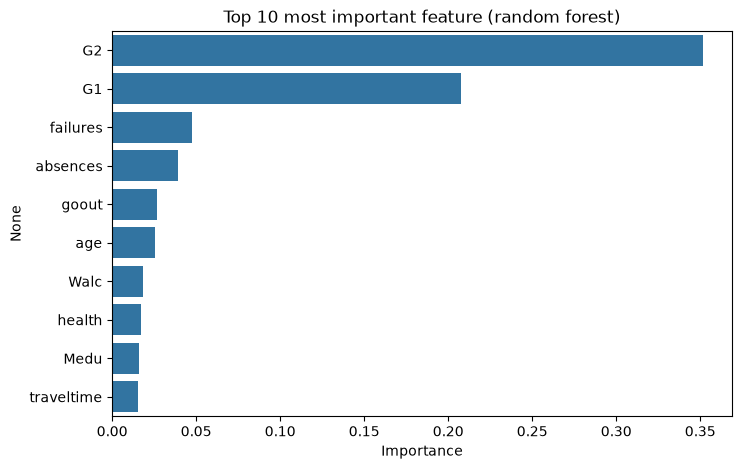

In [19]:
#Feature importance
importances = pd.Series(rf_model.feature_importances_, index = X_train.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize = (8,5))
sns.barplot(x=top10.values, y=top10.index)
plt.title("Top 10 most important feature (random forest)")
plt.xlabel("Importance")
plt.show()

## Model results (with G1 and G2)
- Baseline (always pass): 67.1%
- Logistic Regression: 88.6%
- Random Forest: 87.3%
- The most important features were G2, G1 and failures.
- G2 and G1 together make up more than half of the total feature importance.
  Both models are much better than the baseline, but G1 and G2 are earlier
  grades, so the model may be using grades to predict grades.
- Other features like absences, goout and age matter much less.

## Experiment: with and without G1 and G2

G1 and G2 are grades from earlier in the year. They are very strongly linked
to the final grade, so a model can use them to get high accuracy. But in real
life, we would like to find at-risk students EARLY, before those grades exist.
So I train a second model without G1 and G2 and compare the results.

In [20]:
X_no_grades = X.drop(columns=["G1", "G2"])

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_no_grades, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train2.shape)
print("Test set:", X_test2.shape)

Training set: (316, 39)
Test set: (79, 39)


In [21]:
#Train both models again
log_model2 = LogisticRegression(max_iter=5000)
log_model2.fit(X_train2, y_train2)
log_acc2 = accuracy_score(y_test2, log_model2.predict(X_test2))

rf_model2 = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model2.fit(X_train2, y_train2)
rf_acc2 = accuracy_score(y_test2, rf_model2.predict(X_test2))

print("Logistic Regression (no G1/G2):", round(log_acc2, 3))
print("Random Forest (no G1/G2):", round(rf_acc2, 3))

Logistic Regression (no G1/G2): 0.658
Random Forest (no G1/G2): 0.658


In [22]:
#Compare everything in one table
final_results = pd.DataFrame({
    "Model": ["Baseline (always pass)",
              "Logistic Regression", "Random Forest",
              "Logistic Regression (no G1/G2)", "Random Forest (no G1/G2)"],
    "Accuracy": [baseline, log_acc, rf_acc, log_acc2, rf_acc2]
})
final_results

,Model,Accuracy
0,Baseline (always pass),0.670886
1,Logistic Regression,0.886076
2,Random Forest,0.873418
3,Logistic Regression (no G1/G2),0.658228
4,Random Forest (no G1/G2),0.658228


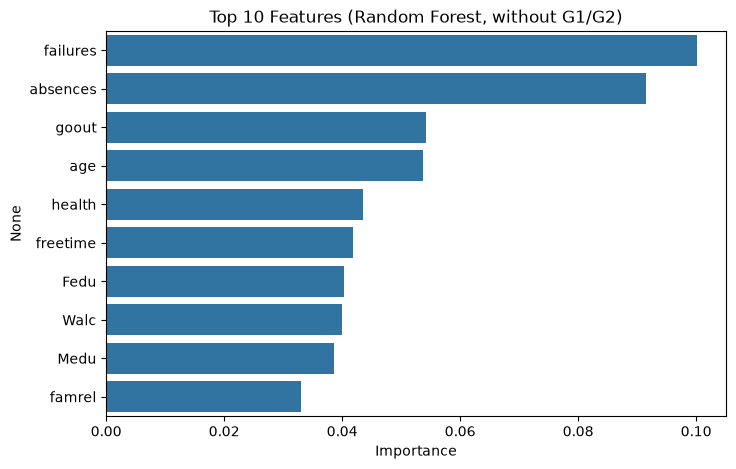

In [23]:
#Feature importance without G1/G2
importances2 = pd.Series(rf_model2.feature_importances_, index=X_train2.columns)
top10_2 = importances2.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10_2.values, y=top10_2.index)
plt.title("Top 10 Features (Random Forest, without G1/G2)")
plt.xlabel("Importance")
plt.show()

## Findings
- With G1 and G2, Logistic Regression reached 88.6% and Random Forest 87.3%
  accuracy, well above the baseline of 67.1%.
- Without G1 and G2, both models dropped to 65.8%, which is about the same
  as the baseline (67.1%). The difference is only one student out of 79.
- This shows that almost all of the predictive power came from the earlier
  grades G1 and G2. Study habits and family background alone were not enough
  to predict pass/fail on this dataset.
- Without G1/G2, the most important feature was (check your chart and write it).
- Limitation: the test set has only 79 students, so small differences are
  not reliable.

In [24]:
import joblib

joblib.dump(rf_model, "../models/model_with_grades.pkl")
joblib.dump(rf_model2, "../models/model_no_grades.pkl")
joblib.dump(list(X_no_grades.columns), "../models/columns_no_grades.pkl")
print("Saved!")

Saved!
